# Support Vector Regression

**Estimator:** `svr`  
**Description:** RBF-kernel Support Vector Regression.

Drop this single notebook into your project `baseline/` directory and run from top to bottom. It discovers `data/unified.parquet` automatically when launched from the project root or a subfolder. The notebook is self-contained: it does not import any helper `.py` files.

**Target:** cycle-level SOH (%) from labelled NASA/CALCE cells. Mobile2Mobile is excluded from supervised fitting because its current unified schema does not provide a comparable measured-capacity SOH label.

**Data contract:** `data/unified.parquet` is already one row per discharge cycle. This notebook uses cycle-level voltage/current/temperature summaries, optional impedance measurements, cycle index and source dataset. It does not aggregate the file again. Measured capacity, first-cycle capacity, SOH, duration and capacity counters are never predictors.

**Parquet schema:** this baseline reads the cycle-level export from `analysis(6).ipynb`: `cycle_order`, `voltage_*_V`, `current_abs_*_A`, `temperature_*_C`, `source_dataset`, `battery_family`, and `soh_pct`. Capacity and audit columns are never predictors.

## Evaluation protocol and leakage control

- **Outer split:** Leave-One-Cell-Out (LOCO). Every cycle from one battery cell is held out together. The same deterministic folds are used in every baseline.
- **Chronology:** measurements are aggregated into cycle-level samples and ordered by cycle index/time. BiLSTM windows end at the cycle being predicted and use no future cycles.
- **Preprocessing:** numeric imputation, categorical imputation/one-hot encoding, feature scaling and target scaling are fitted separately on each training fold only. Test data are transformed with those fitted objects.
- **Metrics:** predictions and uncertainty are inverse-transformed to original SOH percentage units before MAE, MSE, RMSE, R², MAPE, NLL, 95% PICP and MPIW are calculated.
- **Final inference model:** after LOCO evaluation, a final model is refitted on all labelled NASA/CALCE cycles and saved under `models/`.

**Uncertainty note:** GPR models provide posterior standard deviations; Random Forest uses tree spread plus residual noise; other deterministic models use a Gaussian residual-scale approximation estimated on their training fold. Interpret their NLL/PICP/MPIW accordingly.

## 1. Install dependencies

In [1]:
%pip install -q numpy pandas scipy scikit-learn matplotlib joblib pyarrow psutil shap lime

Note: you may need to restart the kernel to use updated packages.


## 2. Imports, paths and reproducibility

In [2]:
from pathlib import Path
import os, re, json, time, random, warnings, math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, Matern, WhiteKernel
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    import psutil
except ImportError:
    psutil = None

try:
    import torch
    from torch import nn
    from torch.utils.data import DataLoader, TensorDataset
except ImportError:
    torch = nn = DataLoader = TensorDataset = None

try:
    import gpytorch
except ImportError:
    gpytorch = None

RANDOM_SEED = 42
TARGET = 'soh_pct'
SEQUENCE_LENGTH = 8
MAX_EXACT_GP_SAMPLES = 1500
DATA_DIR_OVERRIDE = None


def set_seed(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    if torch is not None:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
        try:
            torch.use_deterministic_algorithms(True, warn_only=True)
        except Exception:
            pass

set_seed(RANDOM_SEED)



def locate_data_dir(override=None):
    if override is not None:
        p = Path(override).expanduser().resolve()
        if not p.exists() or not (p / 'unified.parquet').is_file():
            raise FileNotFoundError(f'Expected a genuine unified.parquet inside: {p}')
        return p.parent, p
    cwd = Path.cwd().resolve()
    for root in [cwd, *cwd.parents]:
        for candidate in (root / 'data', root / 'PBL' / 'data'):
            if candidate.is_dir() and (candidate / 'unified.parquet').is_file():
                return candidate.parent, candidate
    raise FileNotFoundError(
        'Could not locate data/unified.parquet. Run this notebook from your PBL project, '
        'or set DATA_DIR_OVERRIDE to the directory containing unified.parquet.'
    )

print('Seed:', RANDOM_SEED)
print('Working directory:', Path.cwd().resolve())
print('Torch:', torch.__version__ if torch is not None else 'not installed')
print('GPyTorch:', gpytorch.__version__ if gpytorch is not None else 'not installed')


/home/raj/Documents/Projects/PBL/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Seed: 42
Working directory: /home/raj/Documents/Projects/PBL/baseline
Torch: 2.15.0+cu132
GPyTorch: 1.15.2


## 3. Load the existing cycle-level unified Parquet (do not aggregate again)

In [3]:
EXPECTED_CELL_COUNT = 47

NUMERIC_FEATURE_CANDIDATES = [
    'cycle_order',
    'voltage_mean_V', 'voltage_std_V', 'voltage_min_V', 'voltage_max_V',
    'voltage_median_V', 'voltage_q10_V', 'voltage_q90_V',
    'current_abs_mean_A', 'current_abs_std_A', 'current_abs_median_A',
    'temperature_mean_C', 'temperature_std_C', 'temperature_min_C', 'temperature_max_C',
]
CATEGORICAL_FEATURE_CANDIDATES = ['source_dataset', 'battery_family']

FORBIDDEN_FEATURES = {
    TARGET, 'measured_discharge_capacity_Ah', 'nominal_capacity_Ah',
    'capacity_integration_Ah', 'capacity_counter_delta_Ah',
    'soh_flag', 'raw_cycle_index', 'cycle_id', 'entity_id', 'cell_group',
    'source_file', 'source_sheet', 'cycle_start_time', 'cycle_end_time',
    'voltage_min_check_V', 'voltage_max_check_V',
    'discharge_sample_count', 'discharge_duration_s',
    'measured_capacity_Ah', 'first_valid_discharge_capacity_Ah',
    'capacity_raw_Ah', 'capacity_source_field', 'capacity_source_unit',
}


def load_measurements(data_dir=None):
    project_root, data_path = locate_data_dir(data_dir)
    parquet_path = data_path / 'unified.parquet'
    try:
        frame = pd.read_parquet(parquet_path, engine='pyarrow')
    except Exception as exc:
        raise RuntimeError(
            f'Could not read {parquet_path} as Parquet. Regenerate it using the validated analysis notebook.'
        ) from exc

    required = {
        'source_dataset', 'battery_family', 'entity_id', 'cycle_id',
        'cycle_order', TARGET,
    }
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(
            'unified.parquet schema mismatch. Missing required columns: '
            f'{sorted(missing)}. Expected the schema exported by analysis(6).ipynb.'
        )

    frame = frame.copy()
    frame['source_dataset'] = frame['source_dataset'].astype('string').str.strip().str.upper()
    sources = set(frame['source_dataset'].dropna().unique())
    if sources != {'NASA', 'CALCE'}:
        raise ValueError(f'Expected exactly NASA and CALCE rows; found {sorted(sources)}')

    for col in ['entity_id', 'cycle_id', 'battery_family']:
        frame[col] = frame[col].astype('string').str.strip()
    if frame[['source_dataset', 'entity_id', 'cycle_id', 'battery_family']].isna().any().any():
        raise ValueError('Source, cell, cycle or battery-family metadata contains missing values.')
    if frame[['entity_id', 'cycle_id', 'battery_family']].astype(str).apply(lambda s: s.str.len().eq(0)).any().any():
        raise ValueError('Cell/cycle/family metadata contains empty strings.')

    dup = frame.duplicated(['source_dataset', 'entity_id', 'cycle_id'], keep=False)
    if dup.any():
        example = frame.loc[dup, ['source_dataset', 'entity_id', 'cycle_id']].head(12)
        raise ValueError('Duplicate source/cell/cycle rows found:\n' + example.to_string(index=False))

    frame[TARGET] = pd.to_numeric(frame[TARGET], errors='coerce')
    if not np.isfinite(frame[TARGET].to_numpy(dtype=float)).all():
        raise ValueError('SOH contains NaN or infinite values.')
    if ((frame[TARGET] < 10) | (frame[TARGET] > 130)).any():
        bad = frame.loc[~frame[TARGET].between(10, 130),
                        ['source_dataset', 'entity_id', 'cycle_id', TARGET]].head(12)
        raise ValueError('SOH outside the 10–130% audit bounds:\n' + bad.to_string(index=False))

    frame['cycle_order'] = pd.to_numeric(frame['cycle_order'], errors='coerce')
    if frame['cycle_order'].isna().any() or not np.isfinite(frame['cycle_order']).all():
        raise ValueError('cycle_order must be finite and numeric for chronology and BiLSTM sequences.')

    print('Loaded:', parquet_path)
    print('Rows:', f'{len(frame):,}')
    print('Cells:', frame[['source_dataset', 'entity_id']].drop_duplicates().shape[0])
    print('Rows by source:', frame.groupby('source_dataset').size().to_dict())
    return frame, project_root, parquet_path


def build_cycle_table(measurements, require_labels=True):
    df = measurements.copy()
    required = {'source_dataset', 'battery_family', 'entity_id', 'cycle_id', 'cycle_order'}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f'Cycle-level rows missing columns: {sorted(missing)}')

    df['source_dataset'] = df['source_dataset'].astype('string').str.strip().str.upper()
    df['entity_id'] = df['entity_id'].astype('string').str.strip()
    df['cycle_id'] = df['cycle_id'].astype('string').str.strip()
    df['battery_family'] = df['battery_family'].astype('string').str.strip()
    df['cycle_order'] = pd.to_numeric(df['cycle_order'], errors='coerce')
    if df['cycle_order'].isna().any() or not np.isfinite(df['cycle_order']).all():
        raise ValueError('cycle_order must be numeric and finite.')

    if TARGET not in df.columns:
        df[TARGET] = np.nan
    df[TARGET] = pd.to_numeric(df[TARGET], errors='coerce')
    if require_labels:
        if df[TARGET].isna().any() or not np.isfinite(df[TARGET].to_numpy(dtype=float)).all():
            raise ValueError('Missing or non-finite SOH labels.')
        if not df[TARGET].between(10, 130).all():
            raise ValueError('SOH values outside 10–130%; review the analysis cell audit.')

    dup = df.duplicated(['source_dataset', 'entity_id', 'cycle_id'], keep=False)
    if dup.any():
        raise ValueError('Duplicate source/cell/cycle rows found; resolve them upstream.')

    df['cycle_index'] = df['cycle_order'].astype(float)
    df['cell_group'] = df['source_dataset'].astype(str) + '::' + df['entity_id'].astype(str)
    df = df.sort_values(
        ['source_dataset', 'entity_id', 'cycle_order', 'cycle_id'], kind='mergesort'
    ).reset_index(drop=True)
    return df.replace([np.inf, -np.inf], np.nan)


def get_feature_columns(cycles):
    numeric = [c for c in NUMERIC_FEATURE_CANDIDATES if c in cycles.columns]
    categorical = [c for c in CATEGORICAL_FEATURE_CANDIDATES if c in cycles.columns]

    missing_numeric = [c for c in NUMERIC_FEATURE_CANDIDATES if c not in cycles.columns]
    if missing_numeric:
        warnings.warn(
            'Some documented predictors are absent from this Parquet and will be skipped: '
            + ', '.join(missing_numeric), RuntimeWarning
        )

    numeric = [
        c for c in numeric
        if pd.to_numeric(cycles[c], errors='coerce').notna().sum() > 0
        and pd.to_numeric(cycles[c], errors='coerce').nunique(dropna=True) > 1
    ]
    categorical = [
        c for c in categorical
        if cycles[c].notna().any() and cycles[c].nunique(dropna=True) > 1
    ]

    expected_signal = {'voltage_mean_V', 'current_abs_mean_A'}
    if not expected_signal.issubset(set(numeric)):
        raise ValueError(
            'Required cycle-summary signals are missing/constant: '
            f'{sorted(expected_signal - set(numeric))}. Check unified.parquet and analysis(6).ipynb.'
        )
    if not numeric:
        raise ValueError('No numeric predictors available.')
    if not categorical:
        warnings.warn('No categorical predictors available.', RuntimeWarning)

    leaked = (set(numeric) | set(categorical)) & FORBIDDEN_FEATURES
    if leaked:
        raise AssertionError(f'Target/audit leakage in predictors: {sorted(leaked)}')
    return numeric, categorical


measurements, PROJECT_ROOT, UNIFIED_PATH = load_measurements(DATA_DIR_OVERRIDE)
cycles = build_cycle_table(measurements, require_labels=True)
NUMERIC_FEATURES, CATEGORICAL_FEATURES = get_feature_columns(cycles)
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES

CELL_GROUPS = sorted(cycles['cell_group'].astype(str).unique())
if len(CELL_GROUPS) != EXPECTED_CELL_COUNT:
    warnings.warn(
        f'Expected {EXPECTED_CELL_COUNT} unique source+cell groups; found {len(CELL_GROUPS)}.',
        RuntimeWarning
    )
if len(CELL_GROUPS) < 2:
    raise ValueError('LOCO requires at least two independent cells.')

print('\nMODEL INPUT CONTRACT')
print('Numeric features:', NUMERIC_FEATURES)
print('Categorical features:', CATEGORICAL_FEATURES)
print('Forbidden capacity/target fields are not model inputs.')
print('Target:', TARGET, '| Group:', 'source_dataset::entity_id')
display(cycles.groupby('source_dataset').agg(
    cells=('entity_id', 'nunique'), cycles=('cycle_id', 'count'),
    SOH_min=(TARGET, 'min'), SOH_median=(TARGET, 'median'), SOH_max=(TARGET, 'max')
).reset_index())


Loaded: /home/raj/Documents/Projects/PBL/data/unified.parquet
Rows: 6,124
Cells: 47
Rows by source: {'CALCE': 3562, 'NASA': 2562}

MODEL INPUT CONTRACT
Numeric features: ['cycle_order', 'voltage_mean_V', 'voltage_std_V', 'voltage_min_V', 'voltage_max_V', 'voltage_median_V', 'voltage_q10_V', 'voltage_q90_V', 'current_abs_mean_A', 'current_abs_std_A', 'current_abs_median_A', 'temperature_mean_C', 'temperature_std_C', 'temperature_min_C', 'temperature_max_C']
Categorical features: ['source_dataset', 'battery_family']
Forbidden capacity/target fields are not model inputs.
Target: soh_pct | Group: source_dataset::entity_id


,source_dataset,cells,cycles,SOH_min,SOH_median,SOH_max
0,CALCE,13,3562,14.627750,85.617165,104.974408
1,NASA,34,2562,10.128165,72.778342,122.203122


## 4. Shared train-only preprocessing, sequence generation and metrics

In [4]:
def make_preprocessor(numeric_features, categorical_features):
    transformers = []
    if numeric_features:
        try:
            numeric_imputer = SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)
        except TypeError:
            numeric_imputer = SimpleImputer(strategy='median', add_indicator=True)
        numeric_pipe = Pipeline([
            ('imputer', numeric_imputer),
            ('scaler', StandardScaler()),
        ])
        transformers.append(('num', numeric_pipe, numeric_features))
    if categorical_features:
        try:
            encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        except TypeError:
            encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
        categorical_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', encoder),
        ])
        transformers.append(('cat', categorical_pipe, categorical_features))
    if not transformers:
        raise ValueError('No feature columns available for preprocessing.')
    return ColumnTransformer(
        transformers, remainder='drop', sparse_threshold=0.0,
        verbose_feature_names_out=True,
    )


def transform_fold(train_df, test_df):
    preprocessor = make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)
    X_train = preprocessor.fit_transform(train_df[FEATURE_COLUMNS])
    X_test = preprocessor.transform(test_df[FEATURE_COLUMNS])
    y_scaler = StandardScaler()
    y_train = y_scaler.fit_transform(train_df[[TARGET]]).ravel().astype(np.float32)
    y_test_scaled = y_scaler.transform(test_df[[TARGET]]).ravel().astype(np.float32)
    y_test_raw = test_df[TARGET].to_numpy(dtype=float)
    return (
        preprocessor, y_scaler,
        np.asarray(X_train, dtype=np.float32),
        np.asarray(X_test, dtype=np.float32),
        y_train, y_test_scaled, y_test_raw,
        preprocessor.get_feature_names_out().tolist(),
    )


def make_sequences(table, X, sequence_length=SEQUENCE_LENGTH):
    X = np.asarray(X, dtype=np.float32)
    out = np.zeros((len(table), sequence_length, X.shape[1]), dtype=np.float32)
    for _, indices in table.groupby('cell_group', sort=False).groups.items():
        pos = np.asarray(list(indices), dtype=int)
        order = np.argsort(table.iloc[pos]['cycle_index'].to_numpy(), kind='stable')
        pos = pos[order]
        for j, end_pos in enumerate(pos):
            start = max(0, j - sequence_length + 1)
            window_pos = pos[start:j + 1]
            out[end_pos, -len(window_pos):, :] = X[window_pos]
    return out


def calculate_metrics(y_true, y_pred, y_std):
    y_true = np.asarray(y_true, dtype=float).ravel()
    y_pred = np.asarray(y_pred, dtype=float).ravel()
    y_std = np.maximum(np.asarray(y_std, dtype=float).ravel(), 1e-6)
    residual = y_true - y_pred
    mse = mean_squared_error(y_true, y_pred)
    lower, upper = y_pred - 1.96 * y_std, y_pred + 1.96 * y_std
    return {
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'MSE': float(mse),
        'RMSE': float(np.sqrt(mse)),
        'R2': float(r2_score(y_true, y_pred)) if len(y_true) >= 2 else np.nan,
        'MAPE_pct': float(np.mean(np.abs(residual) / np.maximum(np.abs(y_true), 1e-8)) * 100),
        'NLL': float(np.mean(0.5 * np.log(2 * np.pi * y_std**2) + residual**2 / (2 * y_std**2))),
        'PICP_95_pct': float(np.mean((y_true >= lower) & (y_true <= upper)) * 100),
        'MPIW_95': float(np.mean(upper - lower)),
    }


## 5. Baseline estimator implementation

In [5]:

if torch is not None:
    class _FeedForwardNet(nn.Module):
        def __init__(self, d, kind, dropout=0.15):
            super().__init__()
            if kind == 'wide':
                self.wide = nn.Linear(d, 1)
                self.deep = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
            elif kind == 'deep':
                self.net = nn.Sequential(
                    nn.Linear(d, 128), nn.ReLU(), nn.Dropout(dropout),
                    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout),
                    nn.Linear(64, 32), nn.ReLU(), nn.Dropout(dropout),
                    nn.Linear(32, 1),
                )
            elif kind == 'wide_deep':
                self.wide = nn.Linear(d, 1)
                self.deep = nn.Sequential(
                    nn.Linear(d, 128), nn.ReLU(), nn.Dropout(dropout),
                    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout),
                    nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1),
                )
            else:
                raise ValueError(kind)
            self.kind = kind

        def forward(self, x):
            if self.kind == 'deep':
                return self.net(x)
            return self.wide(x) + self.deep(x)

    class _BiLSTMNet(nn.Module):
        def __init__(self, d, hidden=48, layers=2, dropout=0.15):
            super().__init__()
            self.lstm = nn.LSTM(
                input_size=d, hidden_size=hidden, num_layers=layers,
                batch_first=True, bidirectional=True,
                dropout=dropout if layers > 1 else 0.0,
            )
            self.head = nn.Sequential(
                nn.Linear(hidden * 2, hidden), nn.ReLU(),
                nn.Dropout(dropout), nn.Linear(hidden, 1),
            )

        def forward(self, x):
            seq, _ = self.lstm(x)
            return self.head(seq[:, -1, :])

    class TorchRegressor:
        def __init__(self, kind='deep', epochs=120, batch_size=64, lr=1e-3, weight_decay=1e-4, seed=RANDOM_SEED):
            self.kind, self.epochs, self.batch_size = kind, epochs, batch_size
            self.lr, self.weight_decay, self.seed = lr, weight_decay, seed

        def fit(self, X, y):
            set_seed(self.seed)
            self.device_ = 'cuda' if torch.cuda.is_available() else 'cpu'
            X = np.asarray(X, dtype=np.float32)
            y = np.asarray(y, dtype=np.float32).reshape(-1, 1)
            self.model_ = _FeedForwardNet(X.shape[-1], self.kind).to(self.device_)
            opt = torch.optim.AdamW(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
            loader = DataLoader(
                TensorDataset(torch.from_numpy(X), torch.from_numpy(y)),
                batch_size=min(self.batch_size, max(1, len(X))), shuffle=True,
                generator=torch.Generator().manual_seed(self.seed),
            )
            self.loss_history_ = []
            for _ in range(self.epochs):
                self.model_.train(); losses = []
                for xb, yb in loader:
                    xb, yb = xb.to(self.device_), yb.to(self.device_)
                    opt.zero_grad(set_to_none=True)
                    loss = nn.functional.mse_loss(self.model_(xb), yb)
                    loss.backward(); nn.utils.clip_grad_norm_(self.model_.parameters(), 5.0); opt.step()
                    losses.append(float(loss.detach().cpu()))
                self.loss_history_.append(float(np.mean(losses)))
            self.model_.eval()
            self.residual_std_ = max(float(np.std(y.ravel() - self.predict(X), ddof=1)) if len(y) > 1 else 1.0, 1e-3)
            self.n_features_in_ = X.shape[-1]
            return self

        def predict(self, X):
            X = np.asarray(X, dtype=np.float32)
            self.model_.eval()
            with torch.no_grad():
                return self.model_(torch.from_numpy(X).to(self.device_)).cpu().numpy().ravel()

        def predict_distribution(self, X):
            p = self.predict(X)
            return p, np.full(len(p), self.residual_std_, dtype=float)

    class BiLSTMRegressor:
        def __init__(self, epochs=100, batch_size=64, lr=1e-3, weight_decay=1e-4, seed=RANDOM_SEED):
            self.epochs, self.batch_size, self.lr = epochs, batch_size, lr
            self.weight_decay, self.seed = weight_decay, seed

        def fit(self, X, y):
            set_seed(self.seed)
            self.device_ = 'cuda' if torch.cuda.is_available() else 'cpu'
            X = np.asarray(X, dtype=np.float32)
            y = np.asarray(y, dtype=np.float32).reshape(-1, 1)
            self.model_ = _BiLSTMNet(X.shape[-1]).to(self.device_)
            opt = torch.optim.AdamW(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
            loader = DataLoader(
                TensorDataset(torch.from_numpy(X), torch.from_numpy(y)),
                batch_size=min(self.batch_size, max(1, len(X))), shuffle=True,
                generator=torch.Generator().manual_seed(self.seed),
            )
            self.loss_history_ = []
            for _ in range(self.epochs):
                self.model_.train(); losses = []
                for xb, yb in loader:
                    xb, yb = xb.to(self.device_), yb.to(self.device_)
                    opt.zero_grad(set_to_none=True)
                    loss = nn.functional.mse_loss(self.model_(xb), yb)
                    loss.backward(); nn.utils.clip_grad_norm_(self.model_.parameters(), 5.0); opt.step()
                    losses.append(float(loss.detach().cpu()))
                self.loss_history_.append(float(np.mean(losses)))
            self.model_.eval()
            self.residual_std_ = max(float(np.std(y.ravel() - self.predict(X), ddof=1)) if len(y) > 1 else 1.0, 1e-3)
            return self

        def predict(self, X):
            X = np.asarray(X, dtype=np.float32)
            self.model_.eval()
            with torch.no_grad():
                return self.model_(torch.from_numpy(X).to(self.device_)).cpu().numpy().ravel()

        def predict_distribution(self, X):
            p = self.predict(X)
            return p, np.full(len(p), self.residual_std_, dtype=float)

if gpytorch is not None and torch is not None:
    class _SparseGPModel(gpytorch.models.ApproximateGP):
        def __init__(self, inducing_points):
            q = gpytorch.variational.CholeskyVariationalDistribution(inducing_points.size(0))
            strategy = gpytorch.variational.VariationalStrategy(
                self, inducing_points, q, learn_inducing_locations=True
            )
            super().__init__(strategy)
            self.mean_module = gpytorch.means.ConstantMean()
            self.covar_module = gpytorch.kernels.ScaleKernel(
                gpytorch.kernels.RBFKernel(ard_num_dims=inducing_points.size(-1))
            )

        def forward(self, x):
            return gpytorch.distributions.MultivariateNormal(self.mean_module(x), self.covar_module(x))

    class SparseGPRRegressor:
        def __init__(self, inducing_points=64, epochs=80, batch_size=128, lr=0.01, seed=RANDOM_SEED):
            self.inducing_points, self.epochs, self.batch_size = inducing_points, epochs, batch_size
            self.lr, self.seed = lr, seed

        def fit(self, X, y):
            if gpytorch is None or torch is None:
                raise ImportError('Sparse GPR requires torch and gpytorch. Run the dependency cell first.')
            set_seed(self.seed)
            self.device_ = 'cuda' if torch.cuda.is_available() else 'cpu'
            X = np.asarray(X, dtype=np.float32); y = np.asarray(y, dtype=np.float32)
            m = min(self.inducing_points, len(X))
            inducing = KMeans(n_clusters=m, random_state=self.seed, n_init=3).fit(X).cluster_centers_.astype(np.float32) if len(X) > m else X.copy()
            self.inducing_points_ = inducing
            self.model_ = _SparseGPModel(torch.tensor(inducing, device=self.device_)).to(self.device_)
            self.likelihood_ = gpytorch.likelihoods.GaussianLikelihood().to(self.device_)
            opt = torch.optim.Adam(list(self.model_.parameters()) + list(self.likelihood_.parameters()), lr=self.lr)
            mll = gpytorch.mlls.VariationalELBO(self.likelihood_, self.model_, num_data=len(X))
            loader = DataLoader(
                TensorDataset(torch.from_numpy(X), torch.from_numpy(y)),
                batch_size=min(self.batch_size, len(X)), shuffle=True,
                generator=torch.Generator().manual_seed(self.seed),
            )
            self.loss_history_ = []
            for _ in range(self.epochs):
                self.model_.train(); self.likelihood_.train(); losses = []
                for xb, yb in loader:
                    xb, yb = xb.to(self.device_), yb.to(self.device_)
                    opt.zero_grad(set_to_none=True)
                    loss = -mll(self.model_(xb), yb)
                    loss.backward(); opt.step(); losses.append(float(loss.detach().cpu()))
                self.loss_history_.append(float(np.mean(losses)))
            self.n_features_in_ = X.shape[1]
            return self

        def predict_distribution(self, X):
            X = np.asarray(X, dtype=np.float32)
            self.model_.eval(); self.likelihood_.eval(); means, stds = [], []
            with torch.no_grad(), gpytorch.settings.fast_pred_var():
                for start in range(0, len(X), 2048):
                    xb = torch.tensor(X[start:start+2048], device=self.device_)
                    pred = self.likelihood_(self.model_(xb))
                    means.extend(pred.mean.detach().cpu().numpy().tolist())
                    stds.extend(pred.variance.clamp_min(1e-8).sqrt().detach().cpu().numpy().tolist())
            return np.asarray(means), np.asarray(stds)

        def predict(self, X):
            return self.predict_distribution(X)[0]

    class _DeepKernelGPModel(gpytorch.models.ExactGP):
        def __init__(self, train_x, train_y, likelihood, input_dim, latent_dim=8):
            super().__init__(train_x, train_y, likelihood)
            self.feature_extractor = nn.Sequential(
                nn.Linear(input_dim, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, latent_dim)
            )
            self.mean_module = gpytorch.means.ConstantMean()
            self.covar_module = gpytorch.kernels.ScaleKernel(
                gpytorch.kernels.RBFKernel(ard_num_dims=latent_dim)
            )

        def forward(self, x):
            z = self.feature_extractor(x)
            return gpytorch.distributions.MultivariateNormal(self.mean_module(z), self.covar_module(z))

    class DeepKernelGPRRegressor:
        def __init__(self, latent_dim=8, epochs=100, lr=0.01, max_train_samples=1200, seed=RANDOM_SEED):
            self.latent_dim, self.epochs, self.lr = latent_dim, epochs, lr
            self.max_train_samples, self.seed = max_train_samples, seed

        def fit(self, X, y):
            if gpytorch is None or torch is None:
                raise ImportError('Deep-kernel GPR requires torch and gpytorch. Run the dependency cell first.')
            set_seed(self.seed)
            self.device_ = 'cuda' if torch.cuda.is_available() else 'cpu'
            X = np.asarray(X, dtype=np.float32); y = np.asarray(y, dtype=np.float32)
            if len(X) > self.max_train_samples:
                take = np.sort(np.random.default_rng(self.seed).choice(len(X), self.max_train_samples, replace=False))
                X, y = X[take], y[take]
            self.n_training_used_ = len(X)
            tx, ty = torch.tensor(X, device=self.device_), torch.tensor(y, device=self.device_)
            self.likelihood_ = gpytorch.likelihoods.GaussianLikelihood().to(self.device_)
            self.model_ = _DeepKernelGPModel(tx, ty, self.likelihood_, X.shape[1], self.latent_dim).to(self.device_)
            opt = torch.optim.Adam(list(self.model_.parameters()) + list(self.likelihood_.parameters()), lr=self.lr)
            mll = gpytorch.mlls.ExactMarginalLogLikelihood(self.likelihood_, self.model_)
            self.loss_history_ = []
            for _ in range(self.epochs):
                self.model_.train(); self.likelihood_.train(); opt.zero_grad(set_to_none=True)
                loss = -mll(self.model_(tx), ty)
                loss.backward(); opt.step(); self.loss_history_.append(float(loss.detach().cpu()))
            return self

        def predict_distribution(self, X):
            X = np.asarray(X, dtype=np.float32)
            self.model_.eval(); self.likelihood_.eval()
            with torch.no_grad(), gpytorch.settings.fast_pred_var():
                xb = torch.tensor(X, device=self.device_)
                pred = self.likelihood_(self.model_(xb))
                return pred.mean.cpu().numpy(), pred.variance.clamp_min(1e-8).sqrt().cpu().numpy()

        def predict(self, X):
            return self.predict_distribution(X)[0]
else:
    SparseGPRRegressor = DeepKernelGPRRegressor = None


def make_estimator(model_name, n_features, seed=RANDOM_SEED):
    if model_name == 'gpr_rbf':
        kernel = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(1.0) + WhiteKernel(1e-4, (1e-7, 1e-1))
        return GaussianProcessRegressor(kernel=kernel, alpha=1e-6, normalize_y=False, n_restarts_optimizer=1, random_state=seed)
    if model_name == 'gpr_matern':
        kernel = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(1.0, length_scale_bounds=(1e-2, 1e2), nu=1.5) + WhiteKernel(1e-4, (1e-7, 1e-1))
        return GaussianProcessRegressor(kernel=kernel, alpha=1e-6, normalize_y=False, n_restarts_optimizer=1, random_state=seed)
    if model_name == 'gpr_ard':
        kernel = ConstantKernel(1.0, (1e-2, 1e2)) * RBF(np.ones(n_features), length_scale_bounds=(1e-2, 1e2)) + WhiteKernel(1e-4, (1e-7, 1e-1))
        return GaussianProcessRegressor(kernel=kernel, alpha=1e-6, normalize_y=False, n_restarts_optimizer=1, random_state=seed)
    if model_name == 'sparse_gpr':
        if SparseGPRRegressor is None: raise ImportError('Install torch and gpytorch for Sparse GPR.')
        return SparseGPRRegressor(inducing_points=64, epochs=80, seed=seed)
    if model_name == 'deep_kernel_gpr':
        if DeepKernelGPRRegressor is None: raise ImportError('Install torch and gpytorch for Deep-Kernel GPR.')
        return DeepKernelGPRRegressor(latent_dim=8, epochs=100, seed=seed)
    if model_name == 'svr':
        return SVR(C=10.0, epsilon=0.05, gamma='scale', kernel='rbf')
    if model_name == 'random_forest':
        return RandomForestRegressor(n_estimators=400, max_features=0.8, min_samples_leaf=2, n_jobs=-1, random_state=seed)
    if model_name == 'xgboost':
        try:
            from xgboost import XGBRegressor
        except ImportError as exc:
            raise ImportError('Run the dependency cell to install xgboost.') from exc
        return XGBRegressor(n_estimators=600, max_depth=4, learning_rate=0.025, subsample=0.85, colsample_bytree=0.85, reg_lambda=2.0, objective='reg:squarederror', tree_method='hist', n_jobs=-1, random_state=seed)
    if model_name == 'wide_nn':
        if torch is None: raise ImportError('Install torch to use WideNN.')
        return TorchRegressor(kind='wide', epochs=120, seed=seed)
    if model_name == 'deep_nn':
        if torch is None: raise ImportError('Install torch to use DeepNN.')
        return TorchRegressor(kind='deep', epochs=140, seed=seed)
    if model_name == 'wide_deep_nn':
        if torch is None: raise ImportError('Install torch to use Wide & Deep NN.')
        return TorchRegressor(kind='wide_deep', epochs=140, seed=seed)
    if model_name == 'bilstm':
        if torch is None: raise ImportError('Install torch to use BiLSTM.')
        return BiLSTMRegressor(epochs=120, seed=seed)
    if model_name == 'symbolic_regression':
        try:
            from gplearn.genetic import SymbolicRegressor
        except ImportError as exc:
            raise ImportError('Run the dependency cell to install gplearn.') from exc
        return SymbolicRegressor(
            population_size=800, generations=18, tournament_size=20,
            stopping_criteria=0.005, const_range=(-2.0, 2.0),
            init_depth=(2, 6), function_set=('add', 'sub', 'mul', 'div', 'sqrt', 'log', 'abs', 'neg'),
            metric='mean absolute error', parsimony_coefficient=0.002,
            p_crossover=0.70, p_subtree_mutation=0.10, p_hoist_mutation=0.05, p_point_mutation=0.10,
            max_samples=0.9, verbose=0, feature_names=None, n_jobs=1, random_state=seed,
        )
    raise ValueError(f'Unknown model: {model_name}')


def fit_estimator(model_name, X, y, seed=RANDOM_SEED):
    model = make_estimator(model_name, X.shape[-1], seed)
    X_fit, y_fit = X, y
    if model_name in {'gpr_rbf', 'gpr_matern', 'gpr_ard'} and len(X) > MAX_EXACT_GP_SAMPLES:
        idx = np.sort(np.random.default_rng(seed).choice(len(X), MAX_EXACT_GP_SAMPLES, replace=False))
        X_fit, y_fit = X[idx], y[idx]
        print(f'  Exact GPR cap: fitted on {len(X_fit):,}/{len(X):,} training cycles.')
    start = time.perf_counter()
    model.fit(X_fit, y_fit)
    return model, time.perf_counter() - start


def predict_distribution(model, X_test, X_train, y_train):
    if isinstance(model, GaussianProcessRegressor):
        mean, std = model.predict(X_test, return_std=True)
        return np.asarray(mean).ravel(), np.maximum(np.asarray(std).ravel(), 1e-6)
    if hasattr(model, 'predict_distribution'):
        mean, std = model.predict_distribution(X_test)
        return np.asarray(mean).ravel(), np.maximum(np.asarray(std).ravel(), 1e-6)
    pred = np.asarray(model.predict(X_test)).ravel()
    if isinstance(model, RandomForestRegressor):
        tree_pred = np.vstack([tree.predict(X_test) for tree in model.estimators_])
        spread = tree_pred.std(axis=0)
        train_resid = np.asarray(y_train).ravel() - np.asarray(model.predict(X_train)).ravel()
        noise = max(float(np.std(train_resid, ddof=1)) if len(train_resid) > 1 else 1.0, 1e-3)
        return pred, np.sqrt(spread**2 + noise**2)
    train_resid = np.asarray(y_train).ravel() - np.asarray(model.predict(X_train)).ravel()
    sigma = max(float(np.std(train_resid, ddof=1)) if len(train_resid) > 1 else 1.0, 1e-3)
    return pred, np.full(len(pred), sigma, dtype=float)


def model_input(model_name, table, X):
    return make_sequences(table.reset_index(drop=True), X) if model_name == 'bilstm' else X


## 6. LOCO training, denormalized evaluation and model export

In [6]:
MODEL_NAME = 'svr'
set_seed(RANDOM_SEED)

CELL_GROUPS = sorted(cycles['cell_group'].astype(str).unique())
FOLD_ASSIGNMENTS = {cell: i + 1 for i, cell in enumerate(CELL_GROUPS)}
print('Model:', MODEL_NAME)
print('LOCO cells:', len(CELL_GROUPS))
print('Fold assignment:')
display(pd.DataFrame([{'held_out_cell': c, 'fold': FOLD_ASSIGNMENTS[c]} for c in CELL_GROUPS]))

fold_rows = []
oof_parts = []
fold_fit_times = []
fold_predict_times = []

for fold_no, held_out_cell in enumerate(CELL_GROUPS, start=1):
    test_mask = cycles['cell_group'].astype(str).eq(held_out_cell)
    train_df = cycles.loc[~test_mask].copy().reset_index(drop=True)
    test_df = cycles.loc[test_mask].copy().reset_index(drop=True)
    if train_df.empty or test_df.empty:
        continue

    prep, y_scaler, X_train_2d, X_test_2d, y_train, y_test_scaled, y_test_raw, feature_names = transform_fold(train_df, test_df)
    X_train = model_input(MODEL_NAME, train_df, X_train_2d)
    X_test = model_input(MODEL_NAME, test_df, X_test_2d)

    print(f'\nFold {fold_no}/{len(CELL_GROUPS)} — held out: {held_out_cell} | train cycles: {len(train_df):,} | test cycles: {len(test_df):,}')
    estimator, fit_s = fit_estimator(MODEL_NAME, X_train, y_train, RANDOM_SEED)

    t0 = time.perf_counter()
    pred_scaled, std_scaled = predict_distribution(estimator, X_test, X_train, y_train)
    predict_s = time.perf_counter() - t0
    y_pred = y_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    y_std = np.maximum(std_scaled * float(y_scaler.scale_[0]), 1e-6)
    fold_metric = calculate_metrics(y_test_raw, y_pred, y_std)
    fold_metric.update({
        'held_out_cell': held_out_cell,
        'fold': fold_no,
        'n_train_cycles': len(train_df),
        'n_test_cycles': len(test_df),
        'fit_time_s': fit_s,
        'predict_latency_ms_per_sample': predict_s * 1000 / max(len(test_df), 1),
    })
    fold_rows.append(fold_metric)
    fold_fit_times.append(fit_s)
    fold_predict_times.append(predict_s * 1000 / max(len(test_df), 1))

    oof_parts.append(pd.DataFrame({
        'cell_group': test_df['cell_group'].astype(str).to_numpy(),
        'source_dataset': test_df['source_dataset'].astype(str).to_numpy(),
        'entity_id': test_df['entity_id'].astype(str).to_numpy(),
        'cycle_index': test_df['cycle_index'].to_numpy(),
        'y_true_soh_pct': y_test_raw,
        'y_pred_soh_pct': y_pred,
        'y_std_soh_pct': y_std,
        'fold': fold_no,
    }))
    print(f"  RMSE={fold_metric['RMSE']:.4f} | MAE={fold_metric['MAE']:.4f} | fit={fit_s:.2f}s")

if not oof_parts:
    raise RuntimeError('No LOCO folds completed.')
oof = pd.concat(oof_parts, ignore_index=True)
fold_metrics = pd.DataFrame(fold_rows)
overall_metrics = calculate_metrics(oof['y_true_soh_pct'], oof['y_pred_soh_pct'], oof['y_std_soh_pct'])
overall_metrics.update({
    'model': MODEL_NAME,
    'seed': RANDOM_SEED,
    'n_cells': len(CELL_GROUPS),
    'n_cycles': len(oof),
    'mean_fold_fit_time_s': float(np.mean(fold_fit_times)),
    'total_loco_fit_time_s': float(np.sum(fold_fit_times)),
    'mean_predict_latency_ms_per_sample': float(np.mean(fold_predict_times)),
    'jetson_latency_ms': np.nan,
    'jetson_energy_J': np.nan,
    'jetson_status': 'Not measured here; requires execution on Jetson Orin Nano.',
})

print('\nFitting final inference model on all labelled cycles...')
final_preprocessor = make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)
X_all_2d = np.asarray(final_preprocessor.fit_transform(cycles[FEATURE_COLUMNS]), dtype=np.float32)
final_y_scaler = StandardScaler().fit(cycles[[TARGET]])
y_all_scaled = final_y_scaler.transform(cycles[[TARGET]]).ravel().astype(np.float32)
X_all = model_input(MODEL_NAME, cycles.reset_index(drop=True), X_all_2d)
final_model, final_fit_s = fit_estimator(MODEL_NAME, X_all, y_all_scaled, RANDOM_SEED)

if torch is not None:
    if hasattr(final_model, 'model_') and hasattr(final_model.model_, 'to'):
        final_model.model_.to('cpu')
        final_model.device_ = 'cpu'
    if hasattr(final_model, 'likelihood_') and hasattr(final_model.likelihood_, 'to'):
        final_model.likelihood_.to('cpu')
        if hasattr(final_model, 'device_'):
            final_model.device_ = 'cpu'

probe = X_all[:min(32, len(X_all))]
t0 = time.perf_counter()
_ = predict_distribution(final_model, probe, X_all, y_all_scaled)
latency_ms = (time.perf_counter() - t0) * 1000 / max(len(probe), 1)

MODELS_DIR = PROJECT_ROOT / 'models'
RESULTS_DIR = PROJECT_ROOT / 'baseline_results' / MODEL_NAME
MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_PATH = MODELS_DIR / f'{MODEL_NAME}.joblib'

bundle = {
    'format_version': 1,
    'model_name': MODEL_NAME,
    'target': TARGET,
    'seed': RANDOM_SEED,
    'numeric_features': NUMERIC_FEATURES,
    'categorical_features': CATEGORICAL_FEATURES,
    'feature_columns': FEATURE_COLUMNS,
    'feature_names_transformed': final_preprocessor.get_feature_names_out().tolist(),
    'sequence_length': SEQUENCE_LENGTH if MODEL_NAME == 'bilstm' else None,
    'preprocessor': final_preprocessor,
    'target_scaler': final_y_scaler,
    'model': final_model,
    'training_cells': CELL_GROUPS,
    'training_cycle_count': len(cycles),
    'fit_time_s_full_data': final_fit_s,
    'inference_latency_ms_per_sample': latency_ms,
    'training_note': 'Refit on all labelled NASA/CALCE cycles after LOCO OOF evaluation.',
}
joblib.dump(bundle, ARTIFACT_PATH, compress=3)
artifact_size_mb = ARTIFACT_PATH.stat().st_size / (1024 ** 2)
try:
    process_rss_mb = psutil.Process().memory_info().rss / (1024 ** 2) if psutil else np.nan
except Exception:
    process_rss_mb = np.nan

equation_node_count = np.nan
if MODEL_NAME == 'symbolic_regression':
    try:
        equation_node_count = int(final_model._program.length_)
    except Exception:
        pass

overall_metrics.update({
    'full_fit_time_s': final_fit_s,
    'inference_latency_ms_per_sample': latency_ms,
    'model_artifact_size_MB': artifact_size_mb,
    'host_process_RSS_MB_after_fit': process_rss_mb,
    'equation_node_count': equation_node_count,
})

oof.to_csv(RESULTS_DIR / 'oof_predictions.csv', index=False)
fold_metrics.to_csv(RESULTS_DIR / 'fold_metrics.csv', index=False)
with open(RESULTS_DIR / 'metrics.json', 'w', encoding='utf-8') as f:
    json.dump(overall_metrics, f, indent=2, default=str)
pd.DataFrame([{'cell_group': c, 'fold': FOLD_ASSIGNMENTS[c]} for c in CELL_GROUPS]).to_csv(
    PROJECT_ROOT / 'baseline_results' / 'loco_split_assignments.csv', index=False
)

print('\nSaved inference artifact:', ARTIFACT_PATH)
print('OOF results:', RESULTS_DIR)
print('Artifact size (MB):', round(artifact_size_mb, 3))


Model: svr
LOCO cells: 47
Fold assignment:


,held_out_cell,fold
0,CALCE::CS2_33,1
1,CALCE::CS2_34,2
2,CALCE::CS2_35,3
3,CALCE::CS2_36,4
4,CALCE::CS2_37,5
5,CALCE::CS2_38,6
6,CALCE::CX2_16,7
7,CALCE::CX2_33,8
8,CALCE::CX2_34,9
9,CALCE::CX2_35,10



Fold 1/47 — held out: CALCE::CS2_33 | train cycles: 5,841 | test cycles: 283
  RMSE=7.0885 | MAE=5.9656 | fit=0.83s

Fold 2/47 — held out: CALCE::CS2_34 | train cycles: 5,880 | test cycles: 244
  RMSE=6.0736 | MAE=5.1903 | fit=0.82s

Fold 3/47 — held out: CALCE::CS2_35 | train cycles: 5,863 | test cycles: 261
  RMSE=1.8293 | MAE=1.5292 | fit=0.77s

Fold 4/47 — held out: CALCE::CS2_36 | train cycles: 5,823 | test cycles: 301
  RMSE=1.8606 | MAE=1.5993 | fit=0.78s

Fold 5/47 — held out: CALCE::CS2_37 | train cycles: 5,824 | test cycles: 300
  RMSE=1.0506 | MAE=0.8459 | fit=0.87s

Fold 6/47 — held out: CALCE::CS2_38 | train cycles: 5,824 | test cycles: 300
  RMSE=1.9729 | MAE=1.6412 | fit=0.77s

Fold 7/47 — held out: CALCE::CX2_16 | train cycles: 5,891 | test cycles: 233
  RMSE=5.9753 | MAE=4.5136 | fit=0.78s

Fold 8/47 — held out: CALCE::CX2_33 | train cycles: 5,879 | test cycles: 245
  RMSE=3.1324 | MAE=2.5660 | fit=0.84s

Fold 9/47 — held out: CALCE::CX2_34 | train cycles: 5,861 | tes

## 7. Inference helper

In [7]:
def predict_new_measurements(new_cycles, artifact_or_bundle):
    loaded = joblib.load(artifact_or_bundle) if isinstance(artifact_or_bundle, (str, Path)) else artifact_or_bundle
    table = build_cycle_table(new_cycles, require_labels=False)
    required_features = loaded['numeric_features'] + loaded['categorical_features']
    missing = set(required_features) - set(table.columns)
    if missing:
        raise ValueError(f'Inference rows are missing trained feature columns: {sorted(missing)}')

    X2d = np.asarray(
        loaded['preprocessor'].transform(table[required_features]),
        dtype=np.float32
    )
    if loaded['model_name'] == 'bilstm':
        Xinput = make_sequences(table.reset_index(drop=True), X2d, loaded['sequence_length'])
    else:
        Xinput = X2d

    pred_scaled = np.asarray(loaded['model'].predict(Xinput)).reshape(-1, 1)
    pred = loaded['target_scaler'].inverse_transform(pred_scaled).ravel()
    out_cols = [c for c in ['source_dataset', 'entity_id', 'cycle_id', 'cycle_index'] if c in table]
    result = table[out_cols].copy()
    result['predicted_soh_pct'] = pred
    return result


print('Inference helper defined: predict_new_measurements(cycle_level_rows, ARTIFACT_PATH)')

Inference helper defined: predict_new_measurements(cycle_level_rows, ARTIFACT_PATH)


## 8. Diagnostic plots and per-cell results

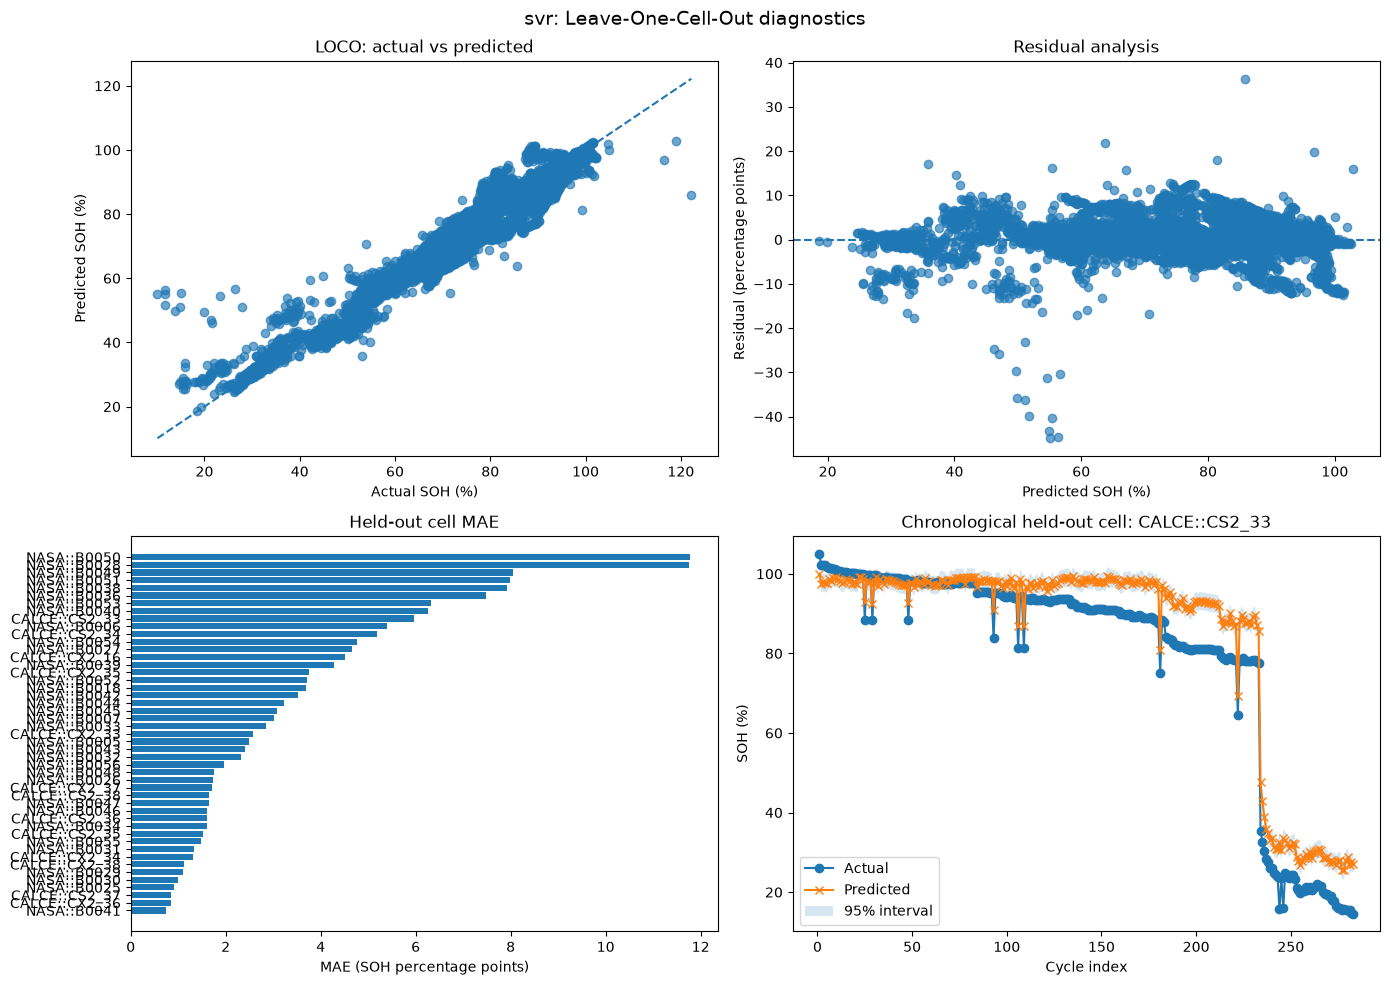

,held_out_cell,n_train_cycles,n_test_cycles,MAE,RMSE,R2,PICP_95_pct,MPIW_95,fit_time_s
0,CALCE::CS2_33,5841,283,5.965641,7.088529,0.934875,23.674912,4.526457,0.827777
1,CALCE::CS2_34,5880,244,5.190274,6.073553,0.704728,29.918033,4.544561,0.820865
2,CALCE::CS2_35,5863,261,1.529181,1.829306,0.993557,80.459770,4.573602,0.774480
3,CALCE::CS2_36,5823,301,1.599265,1.860557,0.993408,80.730897,4.597512,0.783070
4,CALCE::CS2_37,5824,300,0.845873,1.050650,0.997428,97.000000,4.712279,0.871688
5,CALCE::CS2_38,5824,300,1.641206,1.972861,0.991888,75.333333,4.623736,0.770415
6,CALCE::CX2_16,5891,233,4.513570,5.975258,0.306433,41.201717,4.558347,0.775392
7,CALCE::CX2_33,5879,245,2.566007,3.132355,0.969567,55.102041,4.525615,0.835735
8,CALCE::CX2_34,5861,263,1.310127,1.898248,0.983328,81.368821,4.725582,0.791299
9,CALCE::CX2_35,5831,293,3.758843,3.972002,0.798925,7.849829,4.566652,0.763323


Saved diagnostic plots to: /home/raj/Documents/Projects/PBL/baseline_results/svr


In [8]:
oof['residual'] = oof['y_true_soh_pct'] - oof['y_pred_soh_pct']
oof['abs_error'] = np.abs(oof['residual'])
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
ax.scatter(oof['y_true_soh_pct'], oof['y_pred_soh_pct'], alpha=0.65)
lo = float(min(oof['y_true_soh_pct'].min(), oof['y_pred_soh_pct'].min()))
hi = float(max(oof['y_true_soh_pct'].max(), oof['y_pred_soh_pct'].max()))
ax.plot([lo, hi], [lo, hi], linestyle='--')
ax.set_xlabel('Actual SOH (%)'); ax.set_ylabel('Predicted SOH (%)'); ax.set_title('LOCO: actual vs predicted')

ax = axes[0, 1]
ax.scatter(oof['y_pred_soh_pct'], oof['residual'], alpha=0.65)
ax.axhline(0, linestyle='--')
ax.set_xlabel('Predicted SOH (%)'); ax.set_ylabel('Residual (percentage points)'); ax.set_title('Residual analysis')

cell_mae = oof.groupby('cell_group')['abs_error'].mean().sort_values()
ax = axes[1, 0]
ax.barh(cell_mae.index.astype(str), cell_mae.values)
ax.set_xlabel('MAE (SOH percentage points)'); ax.set_title('Held-out cell MAE')

ax = axes[1, 1]
first_cell = sorted(oof['cell_group'].unique())[0]
g = oof[oof['cell_group'] == first_cell].sort_values('cycle_index')
ax.plot(g['cycle_index'], g['y_true_soh_pct'], marker='o', label='Actual')
ax.plot(g['cycle_index'], g['y_pred_soh_pct'], marker='x', label='Predicted')
ax.fill_between(
    g['cycle_index'].to_numpy(),
    (g['y_pred_soh_pct'] - 1.96 * g['y_std_soh_pct']).to_numpy(),
    (g['y_pred_soh_pct'] + 1.96 * g['y_std_soh_pct']).to_numpy(),
    alpha=0.18, label='95% interval'
)
ax.set_xlabel('Cycle index'); ax.set_ylabel('SOH (%)'); ax.set_title(f'Chronological held-out cell: {first_cell}'); ax.legend()

fig.suptitle(f'{MODEL_NAME}: Leave-One-Cell-Out diagnostics', fontsize=14)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'loco_diagnostics.png', dpi=180)
plt.show()

if len(fold_metrics):
    display(fold_metrics[['held_out_cell', 'n_train_cycles', 'n_test_cycles', 'MAE', 'RMSE', 'R2', 'PICP_95_pct', 'MPIW_95', 'fit_time_s']])

if hasattr(final_model, 'loss_history_'):
    plt.figure(figsize=(7, 4))
    plt.plot(final_model.loss_history_)
    plt.xlabel('Epoch'); plt.ylabel('Training loss'); plt.title(f'{MODEL_NAME}: training curve')
    plt.tight_layout(); plt.savefig(RESULTS_DIR / 'training_curve.png', dpi=180); plt.show()

if hasattr(final_model, 'feature_importances_'):
    imp = pd.DataFrame({'feature': bundle['feature_names_transformed'], 'importance': final_model.feature_importances_})
    imp = imp.sort_values('importance', ascending=False).head(20)
    display(imp)
    plt.figure(figsize=(9, 6)); plt.barh(imp['feature'][::-1], imp['importance'][::-1])
    plt.xlabel('Feature importance'); plt.title(f'{MODEL_NAME}: top feature importance')
    plt.tight_layout(); plt.savefig(RESULTS_DIR / 'feature_importance.png', dpi=180); plt.show()

print('Saved diagnostic plots to:', RESULTS_DIR)


## 9. Explainability: SHAP, LIME, PDP, ICE and applicable model-specific analysis

/home/raj/Documents/Projects/PBL/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


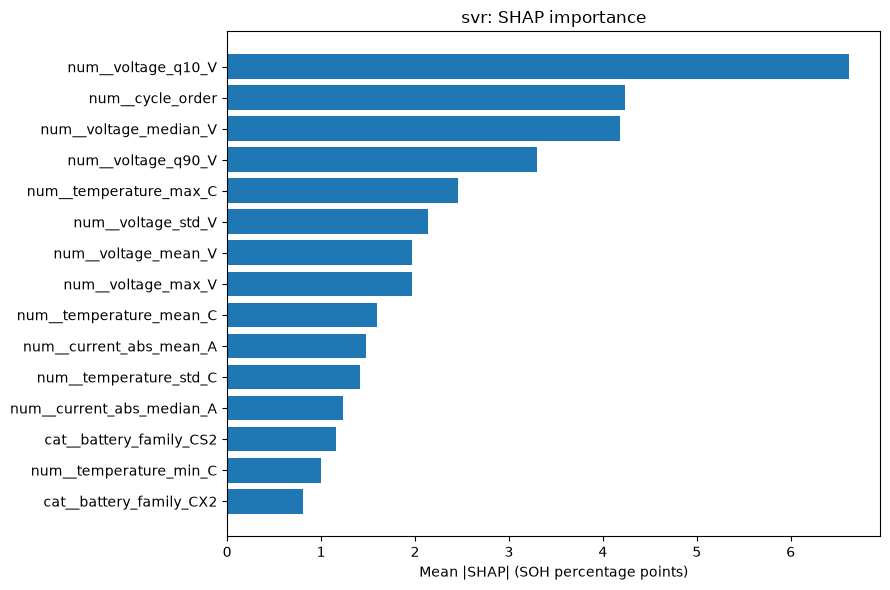

,feature_rule,local_weight
0,num__voltage_q10_V <= -0.41,-18.959431
1,num__voltage_std_V > 0.00,9.303990
2,num__temperature_std_C <= -0.10,5.855272
3,num__voltage_mean_V <= -0.77,-5.497818
4,num__cycle_order <= -1.00,4.148254
5,num__current_abs_std_A > 0.44,3.798900
6,num__temperature_min_C <= 0.18,2.918923
7,num__temperature_mean_C <= 0.17,-2.676246
8,num__voltage_max_V > 0.99,-2.463104
9,cat__battery_family_CX2 <= 0.00,-1.451965


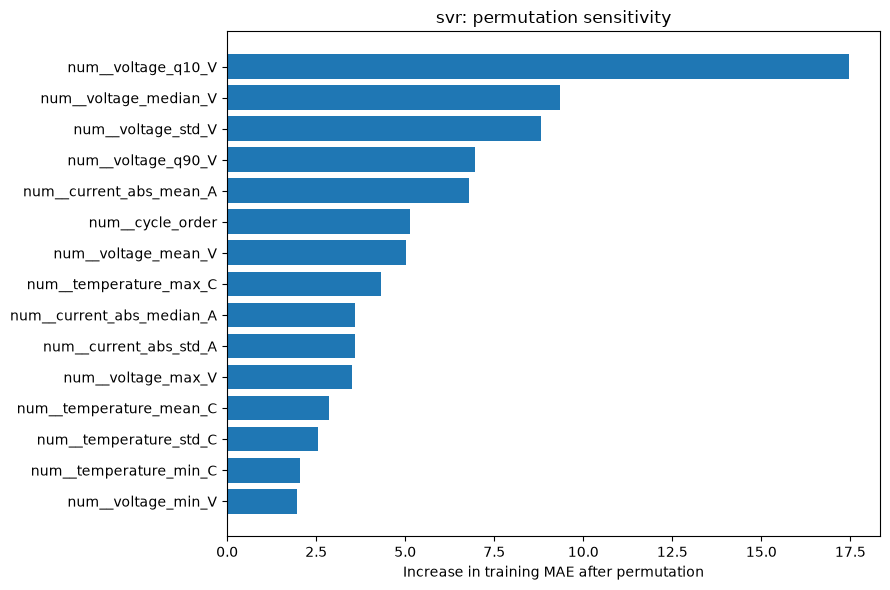

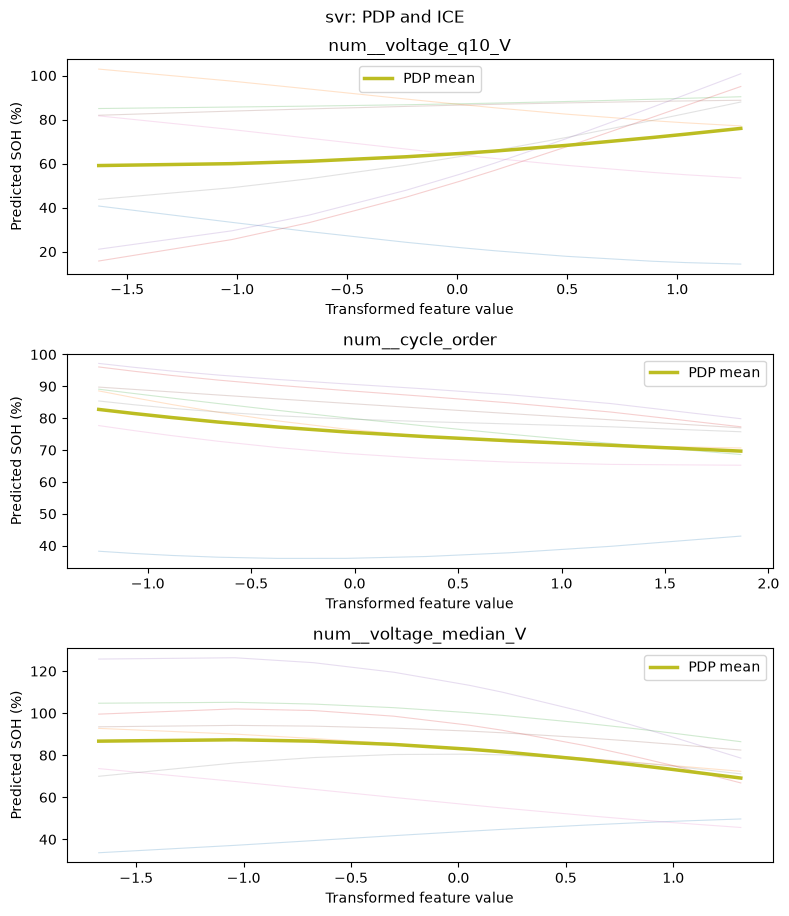

XAI summary:


,method,status,top_features,details
0,SHAP,ok,"num__voltage_q10_V, num__cycle_order, num__vol...",Permutation SHAP on transformed features; glob...
1,LIME,ok,"num__voltage_q10_V <= -0.41, num__voltage_std_...",Local surrogate explanation for one representa...
2,Permutation sensitivity,ok,"num__voltage_q10_V, num__voltage_median_V, num...",Top-variance features; increase in fitted-data...
3,PDP,ok,"num__voltage_q10_V, num__cycle_order, num__vol...",One-way partial dependence for top features in...
4,ICE,ok,"num__voltage_q10_V, num__cycle_order, num__vol...",Individual conditional expectation curves for ...
5,ARD length-scale relevance,not_applicable,,Specific to the ARD-GPR baseline.
6,Symbolic equation + sensitivities,not_applicable,,Specific to standalone symbolic regression; pr...


XAI files: /home/raj/Documents/Projects/PBL/baseline_results/svr/xai


In [9]:
XAI_DIR = RESULTS_DIR / 'xai'
XAI_DIR.mkdir(parents=True, exist_ok=True)
feature_names_xai = bundle['feature_names_transformed']

rng = np.random.default_rng(RANDOM_SEED)
background_n = min(40, len(X_all_2d))
explain_n = min(8, len(X_all_2d))
bg_idx = rng.choice(len(X_all_2d), size=background_n, replace=False)
ex_idx = rng.choice(len(X_all_2d), size=explain_n, replace=False)
background = X_all_2d[bg_idx].copy()
explain_X = X_all_2d[ex_idx].copy()


def xai_predict(transformed_X):
    transformed_X = np.asarray(transformed_X, dtype=np.float32)
    if MODEL_NAME == 'bilstm':
        Xin = np.repeat(transformed_X[:, None, :], SEQUENCE_LENGTH, axis=1)
    else:
        Xin = transformed_X
    pred_scaled = np.asarray(final_model.predict(Xin)).reshape(-1, 1)
    return final_y_scaler.inverse_transform(pred_scaled).ravel()

xai_rows = []
shap_importance = None

try:
    import shap
    explainer = shap.PermutationExplainer(xai_predict, background)
    shap_values = explainer(explain_X[:min(5, len(explain_X))], max_evals=2 * len(feature_names_xai) + 1)
    sv = np.asarray(shap_values.values)
    if sv.ndim == 3:
        sv = sv.mean(axis=-1)
    shap_importance = np.mean(np.abs(sv), axis=0)
    shap_table = pd.DataFrame({'feature': feature_names_xai, 'mean_abs_SHAP': shap_importance}).sort_values('mean_abs_SHAP', ascending=False)
    shap_table.to_csv(XAI_DIR / 'shap_importance.csv', index=False)
    top = shap_table.head(15).sort_values('mean_abs_SHAP')
    plt.figure(figsize=(9, 6)); plt.barh(top['feature'], top['mean_abs_SHAP'])
    plt.xlabel('Mean |SHAP| (SOH percentage points)'); plt.title(f'{MODEL_NAME}: SHAP importance')
    plt.tight_layout(); plt.savefig(XAI_DIR / 'shap_importance.png', dpi=180); plt.show()
    xai_rows.append({'method': 'SHAP', 'status': 'ok', 'top_features': ', '.join(shap_table.head(5)['feature'].astype(str)), 'details': 'Permutation SHAP on transformed features; global mean absolute attribution.'})
except Exception as exc:
    shap_table = pd.DataFrame(columns=['feature', 'mean_abs_SHAP'])
    xai_rows.append({'method': 'SHAP', 'status': 'unavailable', 'top_features': '', 'details': str(exc)[:240]})

try:
    if not hasattr(np, 'float'): np.float = float
    if not hasattr(np, 'int'): np.int = int
    from lime.lime_tabular import LimeTabularExplainer
    lime_explainer = LimeTabularExplainer(
        training_data=background, feature_names=feature_names_xai,
        mode='regression', discretize_continuous=True, random_state=RANDOM_SEED,
    )
    local = lime_explainer.explain_instance(
        explain_X[0], xai_predict, num_features=min(15, len(feature_names_xai)), num_samples=3000
    )
    lime_table = pd.DataFrame(local.as_list(), columns=['feature_rule', 'local_weight'])
    lime_table.to_csv(XAI_DIR / 'lime_local_explanation.csv', index=False)
    display(lime_table)
    xai_rows.append({'method': 'LIME', 'status': 'ok', 'top_features': ', '.join(lime_table.head(5)['feature_rule'].astype(str)), 'details': 'Local surrogate explanation for one representative cycle.'})
except Exception as exc:
    xai_rows.append({'method': 'LIME', 'status': 'unavailable', 'top_features': '', 'details': str(exc)[:240]})

try:
    y_all_raw = cycles[TARGET].to_numpy(dtype=float)
    base_pred = xai_predict(X_all_2d)
    base_mae = mean_absolute_error(y_all_raw, base_pred)
    variance_rank = np.argsort(np.nanvar(X_all_2d, axis=0))[::-1]
    permute_idx = variance_rank[:min(20, X_all_2d.shape[1])]
    permutation_rows = []
    for j in permute_idx:
        perturbed = X_all_2d.copy()
        shuffle_idx = rng.permutation(len(perturbed))
        perturbed[:, j] = perturbed[shuffle_idx, j]
        perturbed_pred = xai_predict(perturbed)
        permuted_mae = mean_absolute_error(y_all_raw, perturbed_pred)
        permutation_rows.append({
            'feature': feature_names_xai[j],
            'baseline_train_MAE': float(base_mae),
            'permuted_train_MAE': float(permuted_mae),
            'MAE_increase': float(permuted_mae - base_mae),
        })
    permutation_table = pd.DataFrame(permutation_rows).sort_values('MAE_increase', ascending=False)
    permutation_table.to_csv(XAI_DIR / 'permutation_sensitivity.csv', index=False)
    top_perm = permutation_table.head(15).sort_values('MAE_increase')
    plt.figure(figsize=(9, 6)); plt.barh(top_perm['feature'], top_perm['MAE_increase'])
    plt.xlabel('Increase in training MAE after permutation'); plt.title(f'{MODEL_NAME}: permutation sensitivity')
    plt.tight_layout(); plt.savefig(XAI_DIR / 'permutation_sensitivity.png', dpi=180); plt.show()
    xai_rows.append({'method': 'Permutation sensitivity', 'status': 'ok', 'top_features': ', '.join(permutation_table.head(5)['feature'].astype(str)), 'details': 'Top-variance features; increase in fitted-data MAE after shuffling. Descriptive, not a held-out score.'})
except Exception as exc:
    xai_rows.append({'method': 'Permutation sensitivity', 'status': 'unavailable', 'top_features': '', 'details': str(exc)[:240]})

try:
    if shap_importance is not None:
        selected_idx = np.argsort(shap_importance)[::-1][:min(3, len(feature_names_xai))]
    else:
        selected_idx = np.argsort(np.nanvar(X_all_2d, axis=0))[::-1][:min(3, len(feature_names_xai))]
    pdp_rows = []
    fig, axes = plt.subplots(len(selected_idx), 1, figsize=(8, 3.1 * max(1, len(selected_idx))), squeeze=False)
    for ax, j in zip(axes.ravel(), selected_idx):
        vals = np.unique(np.quantile(X_all_2d[:, j], np.linspace(0.05, 0.95, 10)))
        if len(vals) < 2:
            ax.set_visible(False); continue
        local_rows = explain_X[:min(8, len(explain_X))]
        curves = []
        for base_row in local_rows:
            varied = np.repeat(base_row.reshape(1, -1), len(vals), axis=0)
            varied[:, j] = vals
            curves.append(xai_predict(varied))
        curves = np.asarray(curves)
        for curve in curves:
            ax.plot(vals, curve, alpha=0.22, linewidth=0.8)
        mean_curve = curves.mean(axis=0)
        ax.plot(vals, mean_curve, linewidth=2.5, label='PDP mean')
        ax.set_title(feature_names_xai[j]); ax.set_xlabel('Transformed feature value'); ax.set_ylabel('Predicted SOH (%)'); ax.legend()
        pdp_rows.append({'feature': feature_names_xai[j], 'pdp_prediction_range': float(mean_curve.max() - mean_curve.min())})
    fig.suptitle(f'{MODEL_NAME}: PDP and ICE')
    fig.tight_layout(); fig.savefig(XAI_DIR / 'pdp_ice.png', dpi=180); plt.show()
    pd.DataFrame(pdp_rows).to_csv(XAI_DIR / 'pdp_ice_summary.csv', index=False)
    selected_names = ', '.join(r['feature'] for r in pdp_rows)
    xai_rows.append({'method': 'PDP', 'status': 'ok' if pdp_rows else 'unavailable', 'top_features': selected_names, 'details': 'One-way partial dependence for top features in transformed feature space.'})
    xai_rows.append({'method': 'ICE', 'status': 'ok' if pdp_rows else 'unavailable', 'top_features': selected_names, 'details': 'Individual conditional expectation curves for representative cycles.'})
except Exception as exc:
    xai_rows.append({'method': 'PDP', 'status': 'unavailable', 'top_features': '', 'details': str(exc)[:240]})
    xai_rows.append({'method': 'ICE', 'status': 'unavailable', 'top_features': '', 'details': str(exc)[:240]})

if MODEL_NAME == 'gpr_ard':
    try:
        kernel = final_model.kernel_
        length_scales = np.asarray(kernel.k1.k2.length_scale).ravel()
        ard_table = pd.DataFrame({
            'feature': feature_names_xai,
            'length_scale': length_scales,
            'relative_relevance_inverse_length': 1.0 / np.maximum(length_scales, 1e-12),
        }).sort_values('relative_relevance_inverse_length', ascending=False)
        ard_table.to_csv(XAI_DIR / 'ard_length_scales.csv', index=False)
        display(ard_table.head(20))
        xai_rows.append({'method': 'ARD length-scale relevance', 'status': 'ok', 'top_features': ', '.join(ard_table.head(5)['feature'].astype(str)), 'details': 'Shorter optimized ARD length scales imply greater sensitivity.'})
    except Exception as exc:
        xai_rows.append({'method': 'ARD length-scale relevance', 'status': 'unavailable', 'top_features': '', 'details': str(exc)[:240]})
else:
    xai_rows.append({'method': 'ARD length-scale relevance', 'status': 'not_applicable', 'top_features': '', 'details': 'Specific to the ARD-GPR baseline.'})

if MODEL_NAME == 'symbolic_regression':
    try:
        program = final_model._program
        equation = str(program)
        equation_node_count = int(getattr(program, 'length_', len(getattr(program, 'program', []))))
        y_mean = float(final_y_scaler.mean_[0]); y_scale = float(final_y_scaler.scale_[0])
        with open(XAI_DIR / 'symbolic_equation.txt', 'w', encoding='utf-8') as f:
            f.write(f'SOH_pct = {y_mean:.10g} + ({y_scale:.10g}) * ({equation})\n\n')
            for i, name in enumerate(feature_names_xai): f.write(f'X{i} = {name}\n')
        center = np.nanmedian(X_all_2d, axis=0).astype(np.float32)
        sens = []
        for j, name in enumerate(feature_names_xai):
            eps = 0.05; xp = center.copy(); xm = center.copy(); xp[j] += eps; xm[j] -= eps
            deriv = float((xai_predict(xp.reshape(1, -1))[0] - xai_predict(xm.reshape(1, -1))[0]) / (2 * eps))
            sens.append({'feature': name, 'dSOH_dstandardized_feature': deriv, 'abs_sensitivity': abs(deriv)})
        sensitivity_table = pd.DataFrame(sens).sort_values('abs_sensitivity', ascending=False)
        sensitivity_table.to_csv(XAI_DIR / 'symbolic_sensitivities.csv', index=False)
        display(sensitivity_table.head(20))
        xai_rows.append({'method': 'Symbolic equation + sensitivities', 'status': 'ok', 'top_features': ', '.join(sensitivity_table.head(5)['feature'].astype(str)), 'details': f'Node count={equation_node_count}; SOH_pct = {y_mean:.5g} + {y_scale:.5g} * ({equation})'})
    except Exception as exc:
        xai_rows.append({'method': 'Symbolic equation + sensitivities', 'status': 'unavailable', 'top_features': '', 'details': str(exc)[:240]})
else:
    xai_rows.append({'method': 'Symbolic equation + sensitivities', 'status': 'not_applicable', 'top_features': '', 'details': 'Specific to standalone symbolic regression; proposed WD-GPR-SR residual equation is a separate model.'})

xai_summary = pd.DataFrame(xai_rows)
xai_summary.to_csv(XAI_DIR / 'xai_summary.csv', index=False)
print('XAI summary:')
display(xai_summary)
print('XAI files:', XAI_DIR)


## 10. Final metrics and XAI tables

In [10]:
metrics_for_display = [
    'MAE', 'MSE', 'RMSE', 'R2', 'MAPE_pct', 'NLL', 'PICP_95_pct', 'MPIW_95',
    'n_cells', 'n_cycles', 'seed', 'mean_fold_fit_time_s', 'total_loco_fit_time_s',
    'mean_predict_latency_ms_per_sample', 'full_fit_time_s',
    'inference_latency_ms_per_sample', 'model_artifact_size_MB',
    'host_process_RSS_MB_after_fit', 'equation_node_count',
    'jetson_latency_ms', 'jetson_energy_J',
]
metrics_table = pd.DataFrame([
    {'Metric': k, 'Value': overall_metrics.get(k, np.nan)} for k in metrics_for_display
])
print('FINAL OUT-OF-FOLD METRICS — SOH in original percentage units')
display(metrics_table)
print('\nXAI METHODS')
display(xai_summary)

with open(RESULTS_DIR / 'final_summary.json', 'w', encoding='utf-8') as f:
    json.dump(overall_metrics, f, indent=2, default=str)
metrics_table.to_csv(RESULTS_DIR / 'final_metrics_table.csv', index=False)
print('\nSaved model:', ARTIFACT_PATH)
print('Saved metrics and plots:', RESULTS_DIR)
print('Jetson energy/latency are intentionally NaN until measured on the Jetson Orin Nano.')


FINAL OUT-OF-FOLD METRICS — SOH in original percentage units


,Metric,Value
0,MAE,2.931901
1,MSE,18.751011
2,RMSE,4.330244
3,R2,0.940372
4,MAPE_pct,4.780814
5,NLL,7.878259
6,PICP_95_pct,57.446114
7,MPIW_95,4.636614
8,n_cells,47.000000
9,n_cycles,6124.000000



XAI METHODS


,method,status,top_features,details
0,SHAP,ok,"num__voltage_q10_V, num__cycle_order, num__vol...",Permutation SHAP on transformed features; glob...
1,LIME,ok,"num__voltage_q10_V <= -0.41, num__voltage_std_...",Local surrogate explanation for one representa...
2,Permutation sensitivity,ok,"num__voltage_q10_V, num__voltage_median_V, num...",Top-variance features; increase in fitted-data...
3,PDP,ok,"num__voltage_q10_V, num__cycle_order, num__vol...",One-way partial dependence for top features in...
4,ICE,ok,"num__voltage_q10_V, num__cycle_order, num__vol...",Individual conditional expectation curves for ...
5,ARD length-scale relevance,not_applicable,,Specific to the ARD-GPR baseline.
6,Symbolic equation + sensitivities,not_applicable,,Specific to standalone symbolic regression; pr...



Saved model: /home/raj/Documents/Projects/PBL/models/svr.joblib
Saved metrics and plots: /home/raj/Documents/Projects/PBL/baseline_results/svr
Jetson energy/latency are intentionally NaN until measured on the Jetson Orin Nano.
